# Inmigrantes entre los ocupados de cada tipo de ocupación

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "ocupaciones-inmigrantes"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Inmigrantes entre los ocupados de cada tipo de ocupación"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # con `categorias`: una serie por grupo de ocupación y sin serie `espana` (vista de categorías)
VISTA = "categorias"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de inmigrantes entre los ocupados de cada ocupación"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de personas nacidas en el extranjero (inmigrantes de primera generación) entre los ocupados de 15 a 64 años de cada gran grupo de ocupación, de los directores y gerentes a las ocupaciones elementales, en España. Una barra más da el porcentaje entre el total de ocupados, como referencia.

**Cómo se lee.** Si el porcentaje de una ocupación es mayor que el del total, los inmigrantes están más representados en ella que en el conjunto del empleo. La web muestra el último año; el CSV guarda la serie de cada ocupación.

**Limitaciones.**
- La concentración en una ocupación no dice por sí sola si los inmigrantes desplazan a otros trabajadores o cubren puestos que no se cubrirían: es la base del debate, no su respuesta.
- Los grandes grupos de la clasificación de ocupaciones (CIUO-08) son muy amplios.
- Es una encuesta: en los grupos con pocos ocupados la estimación es menos fiable (las marcas de Eurostat se recogen en las notas).
- La tabla de Eurostat empieza en 2021.

## 2. Descarga

- **Eurostat `lfsa_egaisedm`**: ocupados de 15 a 64 años, en miles, por situación migratoria (`mgstatus`), gran grupo de ocupación (`isco08`, de `OC1` a `OC9` y `TOTAL`), todos los niveles de estudios (`isced11=TOTAL`), ambos sexos. Se usan `mgstatus=FBO` (nacidos en el extranjero, primera generación) y `mgstatus=TOTAL`. Las fuerzas armadas (`OC0`) no tienen grupo propio en la gráfica.
- **España** en la gráfica y **UE-27** (`EU27_2020`) solo en las notas, como referencia.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat
from lib.tipos import FuenteMeta

# Clave de la categoría: (código CIUO-08 de Eurostat, nombre corto)
OCUPACIONES = {
    "total-ocupados": ("TOTAL", "Total de ocupados"),
    "directores-gerentes": ("OC1", "Directores y gerentes"),
    "profesionales-cientificos": ("OC2", "Profesionales científicos e intelectuales"),
    "tecnicos-apoyo": ("OC3", "Técnicos y profesionales de apoyo"),
    "empleados-administrativos": ("OC4", "Empleados administrativos"),
    "servicios-comercio": ("OC5", "Restauración, comercio y servicios personales"),
    "agricultura-pesca": ("OC6", "Trabajadores agrarios y pesqueros cualificados"),
    "artesanos-oficios": ("OC7", "Oficios de la industria y la construcción"),
    "operadores-maquinaria": ("OC8", "Operadores de maquinaria y montadores"),
    "ocupaciones-elementales": ("OC9", "Ocupaciones elementales"),
}
FILTROS = {"isced11": "TOTAL", "age": "Y15-64", "sex": "T", "unit": "THS_PER"}
GEOS = {"ES": "espana", "EU27_2020": "ue27"}

descargas = {}
for clave, (isco, _) in OCUPACIONES.items():
    for mg in ("FBO", "TOTAL"):
        descargas[clave, mg] = eurostat.get("lfsa_egaisedm", {**FILTROS, "isco08": isco, "mgstatus": mg}, geos=GEOS, desde=DESDE)
estados = {
    clave: eurostat.get_estados("lfsa_egaisedm", {**FILTROS, "isco08": isco, "mgstatus": "FBO"}, geos=GEOS, desde=DESDE)[0]
    for clave, (isco, _) in OCUPACIONES.items()
}
print(descargas["total-ocupados", "FBO"][0].groupby("serie")["periodo"].agg(["min", "max"]))

         min   max
serie             
espana  2021  2025
ue27    2021  2025


## 3. Transformación

1. **Porcentaje de inmigrantes** en cada ocupación y año: ocupados nacidos en el extranjero (`FBO`) entre el total de ocupados de la ocupación (`TOTAL`), por 100.
2. Cada ocupación es una categoría (`categorias`), con su serie y su fuente; la de España va a la gráfica y la de la UE-27, a las notas.
3. **Fiabilidad:** se anotan las ocupaciones y años que Eurostat marca con fiabilidad baja o como no publicables.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


def pct(clave, geo):
    a = descargas[clave, "FBO"][0].set_index(["serie", "periodo"])["valor"]
    b = descargas[clave, "TOTAL"][0].set_index(["serie", "periodo"])["valor"]
    s = (a / b * 100).dropna()
    return s[geo] if geo in s.index.get_level_values(0) else pd.Series(dtype=float)


tabla = pd.DataFrame({clave: pct(clave, "espana") for clave in OCUPACIONES}).sort_index()
tabla_ue = pd.DataFrame({clave: pct(clave, "ue27") for clave in OCUPACIONES}).sort_index()
display(tabla.round(1).T)
df = pd.concat([
    pd.DataFrame({"serie": clave, "periodo": tabla.index, "valor": tabla[clave].values}) for clave in OCUPACIONES
], ignore_index=True)
assert df["valor"].dropna().between(0, 100).all(), "porcentaje fuera de rango"

NOMBRES = {clave: nombre for clave, (_, nombre) in OCUPACIONES.items()}
fuentes = []
for clave, (isco, _) in OCUPACIONES.items():
    f = next(f for f in descargas[clave, "FBO"][1] if f.serie == "espana")
    fuentes.append(FuenteMeta(clave, f.organismo, f"lfsa_egaisedm (isco08={isco}, Y15-64): mgstatus=FBO entre mgstatus=TOTAL",
                              f.url, f.fecha_consulta))

ULTIMO = int(tabla.dropna().index.max())
ULTIMO_UE = int(tabla_ue.dropna().index.max())
ref_ue = "; ".join(f"{NOMBRES[c].lower() if c != 'total-ocupados' else 'total'}, {es(tabla_ue.loc[ULTIMO_UE, c])} %"
                   for c in OCUPACIONES)
marcas = {}
for clave, est in estados.items():
    e = est[(est["serie"] == "espana") & est["estado"].str.contains("u|c", regex=True)]
    if not e.empty:
        marcas[NOMBRES[clave].lower()] = sorted(e["periodo"].astype(int).tolist())
NOTAS = [
    "Eurostat (lfsa_egaisedm): ocupados de 15 a 64 años nacidos en el extranjero (primera generación) en % del total de "
    "ocupados de cada gran grupo de ocupación de la CIUO-08, todos los niveles de estudios, ambos sexos.",
    "El total de ocupados incluye a las fuerzas armadas y a quienes no consta su ocupación, que no tienen barra propia.",
    f"Referencia de la UE-27 (EU27_2020) en {ULTIMO_UE}: {ref_ue}.",
    "La concentración de los inmigrantes en una ocupación no dice por sí sola si desplazan a otros trabajadores o "
    "cubren puestos que no se cubrirían.",
]
if marcas:
    NOTAS.append("Eurostat marca con fiabilidad baja o como dato no publicable en España: "
                 + "; ".join(f"{k} ({', '.join(map(str, v))})" for k, v in marcas.items()) + ".")
for n in NOTAS:
    print("-", n)

periodo,2021,2022,2023,2024,2025
total-ocupados,18.3,19.8,21.3,22.5,23.6
directores-gerentes,14.4,13.8,14.7,16.0,18.5
profesionales-cientificos,8.9,9.3,10.7,11.7,13.0
tecnicos-apoyo,10.6,11.6,12.5,14.0,13.8
empleados-administrativos,11.0,12.1,13.2,14.9,15.3
servicios-comercio,22.7,24.9,27.0,28.8,29.1
agricultura-pesca,15.7,14.0,14.9,17.1,19.4
artesanos-oficios,21.2,23.9,25.9,26.6,28.2
operadores-maquinaria,18.7,20.3,22.8,23.2,25.8
ocupaciones-elementales,38.8,41.5,42.8,44.2,46.7


- Eurostat (lfsa_egaisedm): ocupados de 15 a 64 años nacidos en el extranjero (primera generación) en % del total de ocupados de cada gran grupo de ocupación de la CIUO-08, todos los niveles de estudios, ambos sexos.
- El total de ocupados incluye a las fuerzas armadas y a quienes no consta su ocupación, que no tienen barra propia.
- Referencia de la UE-27 (EU27_2020) en 2025: total, 15,4 %; directores y gerentes, 11,9 %; profesionales científicos e intelectuales, 12,0 %; técnicos y profesionales de apoyo, 10,5 %; empleados administrativos, 10,9 %; restauración, comercio y servicios personales, 18,8 %; trabajadores agrarios y pesqueros cualificados, 6,8 %; oficios de la industria y la construcción, 17,4 %; operadores de maquinaria y montadores, 18,3 %; ocupaciones elementales, 33,8 %.
- La concentración de los inmigrantes en una ocupación no dice por sí sola si desplazan a otros trabajadores o cubren puestos que no se cubrirían.


## 4. Visualización

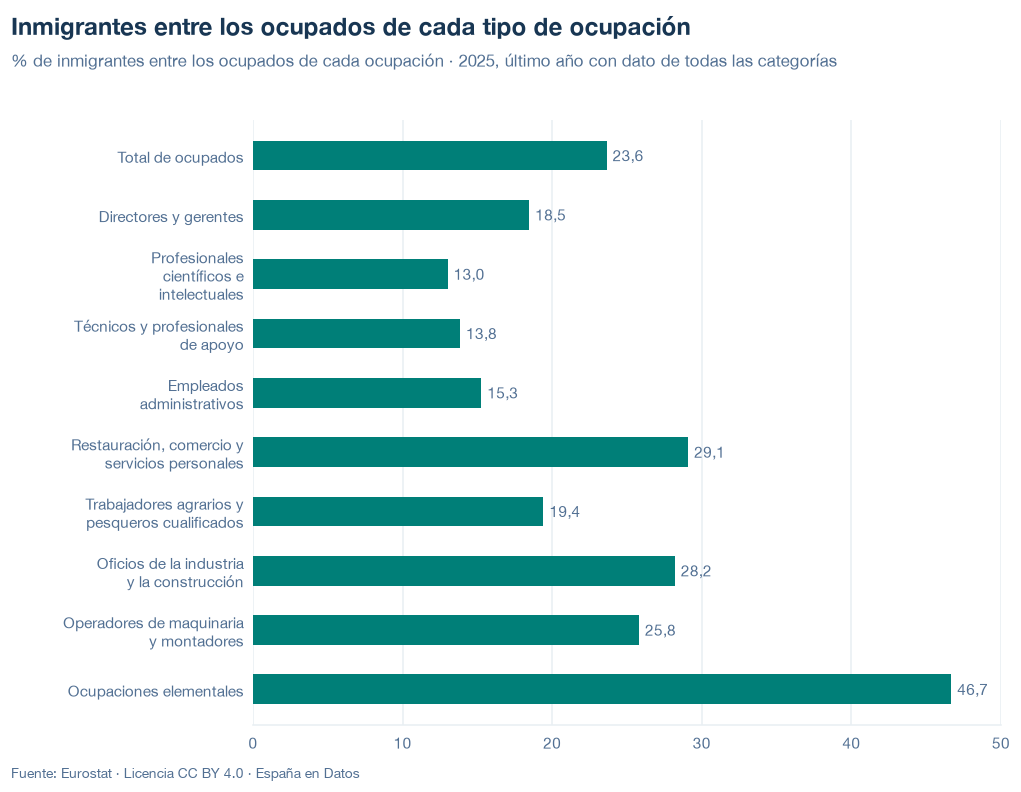

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    categorias=NOMBRES,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    categorias=NOMBRES,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/ocupaciones-inmigrantes.json y data/ocupaciones-inmigrantes.csv


## 6. Fuentes, notas y licencia

- Eurostat, `lfsa_egaisedm` (`mgstatus=FBO` y `TOTAL`, `isco08` de `OC1` a `OC9` y `TOTAL`, `isced11=TOTAL`, `Y15-64`, `T`, `THS_PER`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.